In [ ]:
# ======================================
# Upload Dataset
# ======================================
from google.colab import files
uploaded = files.upload()

import pandas as pd
import io

filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Loaded file:", filename)
df.head()

In [ ]:
# ======================================
# Import Libraries
# ======================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering, MeanShift
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

In [ ]:
# ======================================
# Data Cleaning
# ======================================
print("Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

null_cols = ['fiber','protein','vit_a','vit_c','calcium']
for col in null_cols:
    df[col].fillna(df[col].mean(), inplace=True)

df.drop(['salad','cal_fat','sat_fat','trans_fat'], axis=1, inplace=True)

df.head()

Shape: (515, 17)

Missing Values:
 restaurant       0
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          1
vit_a          214
vit_c          210
calcium        210
salad            0
dtype: int64


/tmp/ipykernel_28979/3824882176.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


,restaurant,item,calories,total_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,7,95,1110,44,3.0,11,37.0,4.0,20.0,20.0
1,Mcdonalds,Single Bacon Smokehouse Burger,840,45,130,1580,62,2.0,18,46.0,6.0,20.0,20.0
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,67,220,1920,63,3.0,18,70.0,10.0,20.0,50.0
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,31,155,1940,62,2.0,18,55.0,6.0,25.0,20.0
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,45,120,1980,81,4.0,18,46.0,6.0,20.0,20.0


In [ ]:
# ======================================
# Prepare Data
# ======================================
df_seg = df.drop(['restaurant','item'], axis=1)

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_seg)

In [ ]:
# ======================================
# Clustering Models
# ======================================

# KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(df_scaled)

# Agglomerative
agg = AgglomerativeClustering(n_clusters=4)
agg_labels = agg.fit_predict(df_scaled)

# GMM
gmm = GaussianMixture(n_components=4, random_state=42)
gmm_labels = gmm.fit_predict(df_scaled)

# DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=5)
db_labels = dbscan.fit_predict(df_scaled)

# Spectral
spectral = SpectralClustering(n_clusters=4, affinity='nearest_neighbors', random_state=42)
spec_labels = spectral.fit_predict(df_scaled)

# Mean Shift (NEW)
meanshift = MeanShift()
ms_labels = meanshift.fit_predict(df_scaled)

# Add labels to dataframe
df['kmeans'] = kmeans_labels
df['agg'] = agg_labels
df['gmm'] = gmm_labels
df['dbscan'] = db_labels
df['spectral'] = spec_labels
df['meanshift'] = ms_labels

In [ ]:
# ======================================
# Silhouette Scores
# ======================================
scores = {}

scores['KMeans'] = silhouette_score(df_scaled, kmeans_labels)
scores['Agglomerative'] = silhouette_score(df_scaled, agg_labels)
scores['GMM'] = silhouette_score(df_scaled, gmm_labels)

# DBSCAN handling
if len(set(db_labels)) > 1:
    scores['DBSCAN'] = silhouette_score(df_scaled[db_labels!=-1], db_labels[db_labels!=-1])
else:
    scores['DBSCAN'] = -1

scores['Spectral'] = silhouette_score(df_scaled, spec_labels)
scores['MeanShift'] = silhouette_score(df_scaled, ms_labels)

score_df = pd.DataFrame(list(scores.items()), columns=['Algorithm','Silhouette Score'])
display(score_df)

,Algorithm,Silhouette Score
0,KMeans,0.270015
1,Agglomerative,0.225939
2,GMM,0.278802
3,DBSCAN,0.571829
4,Spectral,0.061236
5,MeanShift,0.330666


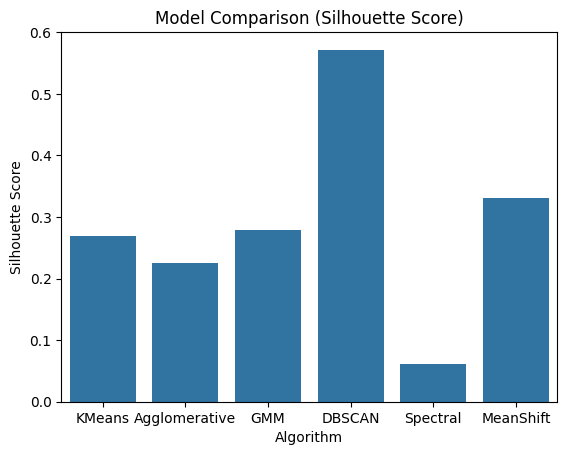

In [ ]:
# ======================================
# Score Visualization
# ======================================
sn.barplot(x='Algorithm', y='Silhouette Score', data=score_df)
plt.title("Model Comparison (Silhouette Score)")
plt.show()

In [ ]:
# ======================================
# Cluster Sizes
# ======================================
models = {
    "KMeans": kmeans_labels,
    "Agglomerative": agg_labels,
    "GMM": gmm_labels,
    "DBSCAN": db_labels,
    "Spectral": spec_labels,
    "MeanShift": ms_labels
}

for name, labels in models.items():
    print(f"\n{name}:\n", pd.Series(labels).value_counts())


KMeans:
 2    274
1    195
3     40
0      6
Name: count, dtype: int64

Agglomerative:
 2    296
0    158
1     32
3     29
Name: count, dtype: int64

GMM:
 2    405
1     69
3     35
0      6
Name: count, dtype: int64

DBSCAN:
  0    483
-1     23
 1      9
Name: count, dtype: int64

Spectral:
 0    328
3     80
2     71
1     36
Name: count, dtype: int64

MeanShift:
 0     441
7      14
2      12
9      11
12     10
1       9
10      6
8       4
5       1
4       1
13      1
3       1
14      1
6       1
15      1
11      1
Name: count, dtype: int64


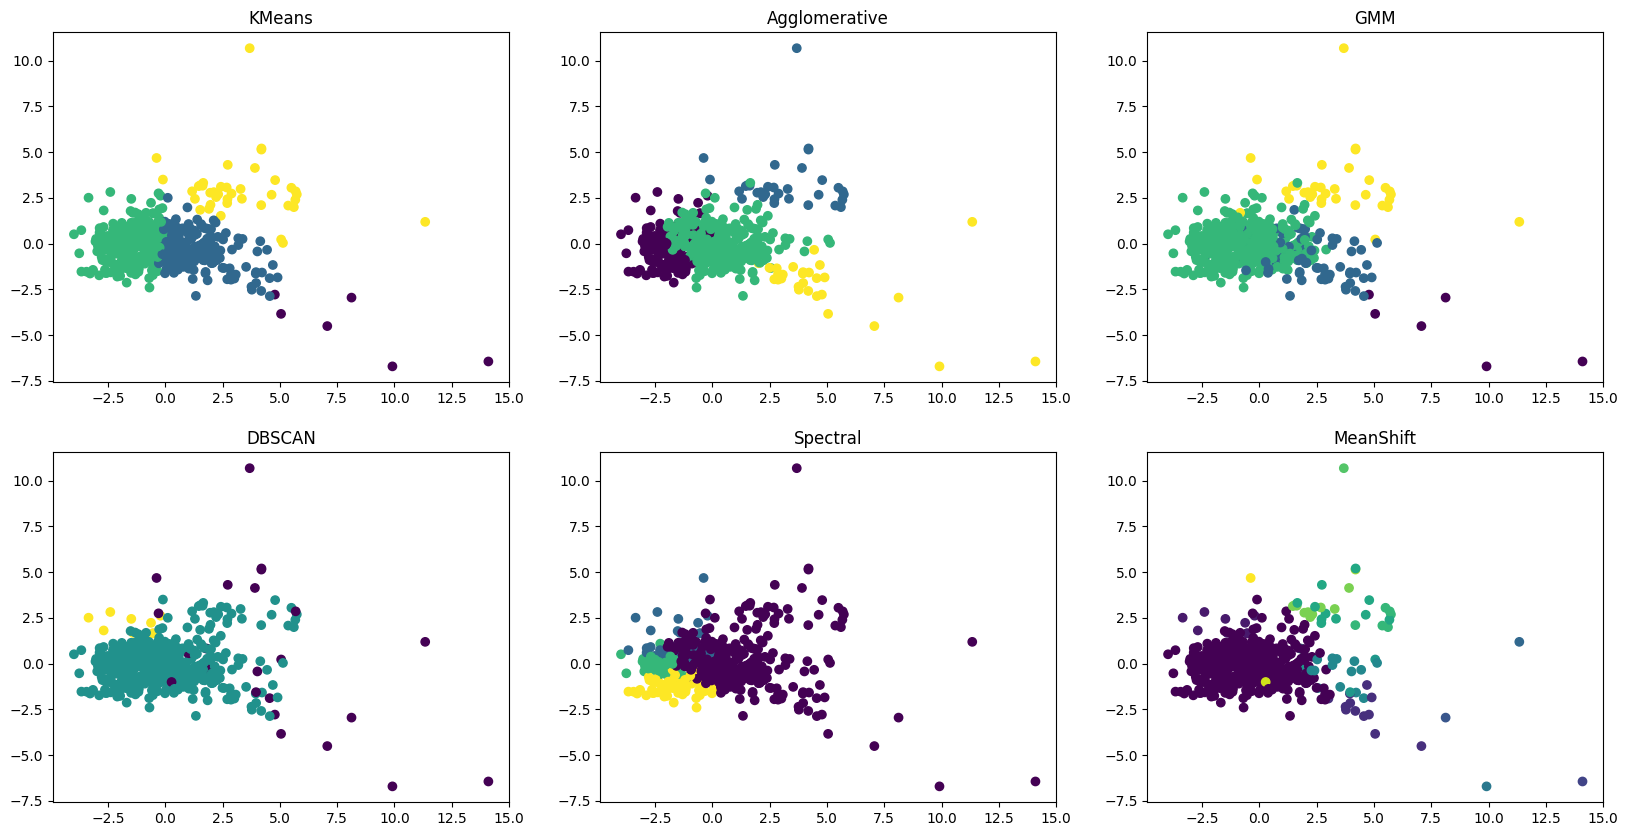

In [ ]:
# ======================================
# PCA Visualization
# ======================================
pca = PCA(n_components=2)
components = pca.fit_transform(df_scaled)

plt.figure(figsize=(20,10))

for i, (name, labels) in enumerate(models.items()):
    plt.subplot(2,3,i+1)
    plt.scatter(components[:,0], components[:,1], c=labels)
    plt.title(name)

plt.show()

In [ ]:
# ======================================
# Comparison Table
# ======================================
comparison_data = []

def get_cluster_info(labels):
    unique_clusters = set(labels)

    if -1 in unique_clusters:
        n_clusters = len(unique_clusters) - 1
        noise = list(labels).count(-1)
    else:
        n_clusters = len(unique_clusters)
        noise = 0

    temp = df.copy()
    temp['cluster'] = labels
    avg_cal = temp.groupby('cluster')['calories'].mean().mean()

    return n_clusters, noise, avg_cal

for name, labels in models.items():

    if name == "DBSCAN":
        if len(set(labels)) > 1:
            score = silhouette_score(df_scaled[labels!=-1], labels[labels!=-1])
        else:
            score = -1
    else:
        score = silhouette_score(df_scaled, labels)

    n_clusters, noise, avg_cal = get_cluster_info(labels)

    comparison_data.append([name, score, n_clusters, noise, avg_cal])

comparison_df = pd.DataFrame(comparison_data,
    columns=["Algorithm","Silhouette Score","Clusters","Noise Points","Avg Calories"]
)

comparison_df = comparison_df.sort_values(by="Silhouette Score", ascending=False)

display(comparison_df)

,Algorithm,Silhouette Score,Clusters,Noise Points,Avg Calories
3,DBSCAN,0.571829,2,23,620.630320
5,MeanShift,0.330666,16,0,1016.045087
2,GMM,0.278802,4,0,914.390384
0,KMeans,0.270015,4,0,863.009697
1,Agglomerative,0.225939,4,0,711.641685
4,Spectral,0.061236,4,0,384.499381


In [ ]:
# ======================================
# PSEUDO-ACCURACY CALCULATION
# ======================================

# Normalize silhouette scores into percentages
min_score = comparison_df['Silhouette Score'].min()
max_score = comparison_df['Silhouette Score'].max()

# Avoid division by zero
comparison_df['Accuracy (%)'] = (
    (comparison_df['Silhouette Score'] - min_score) /
    (max_score - min_score + 1e-9)
) * 100

# Round for clean display
comparison_df['Accuracy (%)'] = comparison_df['Accuracy (%)'].round(2)

print("\n=== UPDATED COMPARISON TABLE WITH ACCURACY ===")
display(comparison_df)


=== UPDATED COMPARISON TABLE WITH ACCURACY ===


,Algorithm,Silhouette Score,Clusters,Noise Points,Avg Calories,Accuracy (%)
3,DBSCAN,0.571829,2,23,620.630320,100.00
5,MeanShift,0.330666,16,0,1016.045087,52.77
2,GMM,0.278802,4,0,914.390384,42.61
0,KMeans,0.270015,4,0,863.009697,40.89
1,Agglomerative,0.225939,4,0,711.641685,32.26
4,Spectral,0.061236,4,0,384.499381,0.00


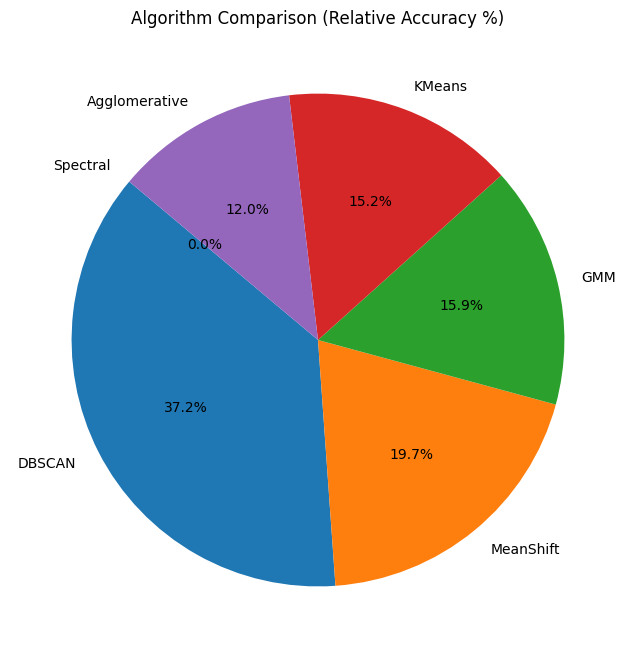

In [ ]:
# ======================================
# PIE CHART - ACCURACY COMPARISON
# ======================================

plt.figure(figsize=(8,8))

plt.pie(
    comparison_df['Accuracy (%)'],
    labels=comparison_df['Algorithm'],
    autopct='%1.1f%%',
    startangle=140
)

plt.title("Algorithm Comparison (Relative Accuracy %)")
plt.show()

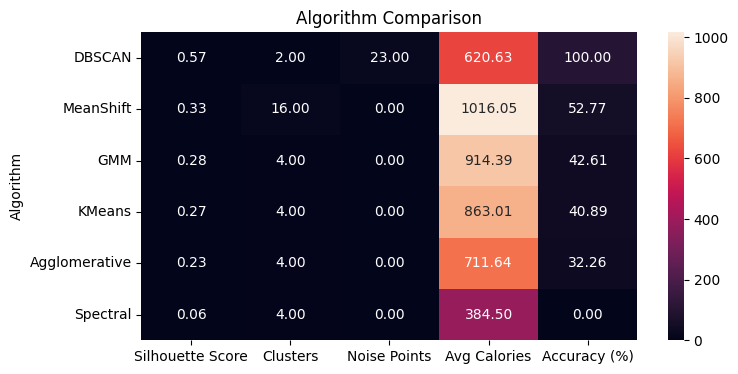

In [ ]:
# ======================================
# Heatmap
# ======================================
plt.figure(figsize=(8,4))
sn.heatmap(comparison_df.set_index("Algorithm"), annot=True, fmt=".2f")
plt.title("Algorithm Comparison")
plt.show()

In [ ]:
# ======================================
# Best Model
# ======================================
best_model = comparison_df.iloc[0]
print("Best Model:\n", best_model)

In [ ]:
# ======================================
# Health Analysis
# ======================================
label_map = {
    'KMeans': 'kmeans',
    'Agglomerative': 'agg',
    'GMM': 'gmm',
    'DBSCAN': 'dbscan',
    'Spectral': 'spectral',
    'MeanShift': 'meanshift'
}

best_name = best_model['Algorithm']
df['best_labels'] = df[label_map[best_name]]

positive = ['protein','calcium','total_carb','vit_a','vit_c','fiber']
negative = ['sugar','calories','total_fat','sodium','cholesterol']

scores = {}

for label, group in df.groupby('best_labels'):
    pos = group[positive].mean().mean()
    neg = group[negative].mean().mean()
    scores[label] = pos - neg

best_cluster = max(scores, key=scores.get)
worst_cluster = min(scores, key=scores.get)

print("\nHealthiest Cluster:", best_cluster)
print(df[df['best_labels']==best_cluster]['item'].unique())

print("\nLeast Healthy Cluster:", worst_cluster)
print(df[df['best_labels']==worst_cluster]['item'].unique())


Healthiest Cluster: 1
['Premium Asian Salad w/o Chicken'
 'Premium Asian Salad w/ Grilled Chicken'
 'Premium Asian Salad w/ Crispy Chicken'
 'Premium Bacon Ranch Salad w/o Chicken'
 'Premium Bacon Ranch Salad w/ Grilled Chicken'
 'Premium Bacon Ranch Salad w/ Crispy Chicken'
 'Premium Southwest Salad w/o Chicken'
 'Premium Southwest Salad w/ Grilled Chicken'
 'Premium Southwest Salad w/ Crispy Chicken']

Least Healthy Cluster: -1
['Crispy Maple Bacon Dijon Chicken Sandwich'
 '10 piece Buttermilk Crispy Chicken Tenders'
 '12 piece Buttermilk Crispy Chicken Tenders'
 '20 piece Buttermilk Crispy Chicken Tenders' '40 piece Chicken McNuggets'
 "4 piece Sweet N' Spicy Honey BBQ Glazed Tenders"
 "6 piece Sweet N' Spicy Honey BBQ Glazed Tenders"
 "10 piece Sweet N' Spicy Honey BBQ Glazed Tenders"
 '30 piece Chicken Nuggets' 'Chargrilled Chicken Cool Wrap'
 'Buffalo Dunked Ultimate Chicken Sandwich' 'American Brewhouse King'
 'Farmhouse King' 'Chicken, Apple & Cranberry Salad w/ Grilled Chicke